In [1]:
# Read-only diagnostic: no training, checkpoint changes, or new model inference.
from pathlib import Path
import os, json, hashlib, datetime, html
import numpy as np
import pandas as pd
import rasterio
from scipy import ndimage
import matplotlib.pyplot as plt
from IPython.display import display
for root in (Path('.'),Path('..'),Path('../..'),Path('../../..')):
    if (root/'src/use_croma.py').is_file():
        os.chdir(root);break
else: raise FileNotFoundError('Open inside the repository.')
OUT=Path('reports/multimodal_diagnostics')/datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
OUT.mkdir(parents=True)
GROUPS={'S1':'UperNet_head_S1','S2':'UperNet_Head_S2','S1S2':'UperNet_head_S1S2'}
RUNS={m:sorted(Path('runs/croma_sen1floods11',g).glob('test_*/metrics_summary.json'))[-1].parent for m,g in GROUPS.items()}
HAND=Path('dataset/sen1floods11_hand_labeled_only/HandLabeled')
META={m:json.loads((r/'run.json').read_text()) for m,r in RUNS.items()}
TRAIN={m:json.loads((Path(d['checkpoint']).parent/'run.json').read_text()) for m,d in META.items()}
HIST={m:json.loads((Path(d['checkpoint']).parent/'croma_training_history.json').read_text()) for m,d in META.items()}
SAVED={m:json.loads((r/'metrics_summary.json').read_text()) for m,r in RUNS.items()}
provenance={'runs':{m:str(p) for m,p in RUNS.items()},'selection':'latest available saved evaluation, not best test score','no_training':True}
(OUT/'provenance.json').write_text(json.dumps(provenance,indent=2))
print('Output:',OUT)
def counts(y,p,valid):
    return np.array([np.count_nonzero(valid&(y==t)&(p==v)) for t,v in [(1,1),(0,1),(1,0),(0,0)]],dtype=np.int64)
def scores(c):
    tp,fp,fn,tn=np.asarray(c,dtype=float)
    div=lambda a,b: a/b if b else np.nan
    wi=div(tp,tp+fp+fn); ni=div(tn,tn+fp+fn)
    return {'miou':np.nanmean([wi,ni]),'water_iou':wi,'precision':div(tp,tp+fp),'recall':div(tp,tp+fn),'f1':div(2*tp,2*tp+fp+fn)}
keys=['epochs','eval_interval','seed','batch_size','crop_size','loss','optimizer','learning_rate','weight_decay','scheduler','checkpoint_selection','backbone_frozen','head_config','inference_grid']
protocol=pd.DataFrame([{'setting':k,**{m:str(d.get(k)) for m,d in TRAIN.items()},'S2_joint_match':TRAIN['S2'].get(k)==TRAIN['S1S2'].get(k)} for k in keys])
protocol.to_csv(OUT/'protocol_comparison.csv',index=False);display(protocol)
architecture=pd.DataFrame([
 {'model':'S2','features':'optical residual blocks 4,6,8,12; stops after block 12 of 24','fusion':'none','frozen':True},
 {'model':'S1S2','features':'joint blocks 4,6,8,12 after full 12-block radar and 24-block optical streams','fusion':'pretrained cross-attention; joint features only','frozen':True}])
architecture.to_csv(OUT/'architecture_audit.csv',index=False);display(architecture)
print('Same head settings do not imply identical feature depth. This is not an isolated radar-addition ablation.')

Output: reports\multimodal_diagnostics\20261028_095846


,setting,S1,S2,S1S2,S2_joint_match
0,epochs,80,80,80,True
1,eval_interval,2,2,2,True
2,seed,234,234,234,True
3,batch_size,8,8,8,True
4,crop_size,120,120,120,True
5,loss,unweighted_cross_entropy,unweighted_cross_entropy,unweighted_cross_entropy,True
6,optimizer,AdamW,AdamW,AdamW,True
7,learning_rate,0.0001,0.0001,0.0001,True
8,weight_decay,0.05,0.05,0.05,True
9,scheduler,"{'name': 'MultiStepLR', 'milestones': [1488, 2...","{'name': 'MultiStepLR', 'milestones': [1488, 2...","{'name': 'MultiStepLR', 'milestones': [1488, 2...",True


,model,features,fusion,frozen
0,S2,"optical residual blocks 4,6,8,12; stops after ...",none,True
1,S1S2,"joint blocks 4,6,8,12 after full 12-block rada...",pretrained cross-attention; joint features only,True


Same head settings do not imply identical feature depth. This is not an isolated radar-addition ablation.


In [2]:
# Check every prediction grid and reproduce saved confusion counts before diagnosis.
metadata=json.loads(Path('experiments/croma_sen1floods11/S1_S2_acquisition_analysis/references/Sen1Floods11_Metadata.geojson').read_text())
dates={f['properties']['location']:f['properties'] for f in metadata['features']}
rows=[];strata=[];cache={};audit=[]
for split in ['non_bol','bol']:
    frames={m:pd.read_csv(r/split/'metrics_per_chip.csv') for m,r in RUNS.items()}
    ids=set(frames['S2'].chip_id)
    assert all(set(f.chip_id)==ids for f in frames.values())
    for chip in sorted(ids):
        with rasterio.open(HAND/'LabelHand'/f'{chip}_LabelHand.tif') as src:
            y=src.read(1);grid=(src.shape,src.crs,src.transform)
        valid=np.isin(y,[0,1]);pred={};conf={}
        for m,r in RUNS.items():
            suffix='S1Hand' if m=='S1' else 'S2Hand';p=r/split/f'{chip}_{suffix}_prediction.tif'
            with rasterio.open(p) as src:
                assert src.shape==grid[0] and src.crs==grid[1] and src.transform.almost_equals(grid[2],precision=1e-10)
                pred[m]=src.read(1)
            assert np.isin(pred[m],[0,1]).all()
            conf[m]=counts(y,pred[m],valid)
            saved=frames[m].set_index('chip_id').loc[chip]
            assert np.array_equal(conf[m],saved[['TP','FP','FN','TN']].to_numpy(dtype=np.int64))
            audit.append({'path':p.as_posix(),'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
        rawvalid={}
        for sensor,bands in [('S1',[1,2]),('S2',[1,2,3,4,5,6,7,8,9,10,12,13])]:
            with rasterio.open(HAND/(sensor+'Hand')/f'{chip}_{sensor}Hand.tif') as src:
                assert src.shape==grid[0] and src.crs==grid[1] and src.transform.almost_equals(grid[2],precision=1e-10)
                raw=src.read(bands,masked=True,out_dtype='float32').filled(np.nan)
            rawvalid[sensor]=np.isfinite(raw).all(axis=0)
        common=rawvalid['S1']&rawvalid['S2'];water=valid&(y==1)
        s2ok=pred['S2']==y;jointok=pred['S1S2']==y
        harm=valid&s2ok&~jointok;rescue=valid&~s2ok&jointok
        region=chip.rsplit('_',1)[0];event=dates.get('Cambodia' if region=='Mekong' else region)
        gap=abs((datetime.datetime.strptime(event['s1_date'],'%Y/%m/%d')-datetime.datetime.strptime(event['s2_date'],'%Y/%m/%d')).days) if event else np.nan
        row={'split':split,'chip':chip,'region':region,'gap_days':gap,'valid_pixels':int(valid.sum()),'water_pixels':int(water.sum()),'water_fraction':float(water.sum()/valid.sum()) if valid.any() else np.nan,'common_input_fraction':float(common.mean()),'usable_joint':bool(common.any()),'harmed_pixels':int(harm.sum()),'rescued_pixels':int(rescue.sum()),'harmed_water':int((harm&water).sum()),'rescued_water':int((rescue&water).sum()),'harmed_background':int((harm&~water).sum()),'rescued_background':int((rescue&~water).sum()),'harm_agrees_with_s1':int((harm&(pred['S1S2']==pred['S1'])).sum())}
        for m,c in conf.items():
            row.update({m+'_'+k:int(v) for k,v in zip(['TP','FP','FN','TN'],c)})
            row.update({m+'_'+k:v for k,v in scores(c).items()})
        row['delta_miou_pp']=100*(row['S1S2_miou']-row['S2_miou']);row['delta_water_iou_pp']=100*(row['S1S2_water_iou']-row['S2_water_iou'])
        rows.append(row)
        # Two-pixel boundary band, excluding two-pixel neighbourhoods of ignored labels.
        core=ndimage.binary_erosion(valid,iterations=2,border_value=0)
        boundary=core&ndimage.binary_dilation(water,iterations=2)&ndimage.binary_dilation(valid&~water,iterations=2)
        masks={'common_valid_input':valid&common,'boundary_2px':boundary,'interior':core&~boundary}
        for category,mask in masks.items():
            for m in ['S2','S1S2']:
                c=counts(y,pred[m],mask);strata.append({'split':split,'chip':chip,'stratum':category,'model':m,**dict(zip(['TP','FP','FN','TN'],c))})
        components,n=ndimage.label(water,structure=np.ones((3,3)));areas=np.bincount(components.ravel());sizes=areas[components]
        for label,lo,hi in [('water_component_1_64px',1,64),('water_component_65_1024px',65,1024),('water_component_over_1024px',1025,np.inf)]:
            mask=water&(sizes>=lo)&(sizes<=hi)
            for m in ['S2','S1S2']:
                c=counts(y,pred[m],mask);strata.append({'split':split,'chip':chip,'stratum':label,'model':m,**dict(zip(['TP','FP','FN','TN'],c))})
        cache[(split,chip)]=(y,pred,harm,rescue)
    print('Verified',split,len(ids),'chips')
paired=pd.DataFrame(rows);paired.to_csv(OUT/'paired_chip_diagnostics.csv',index=False)
pd.DataFrame(audit).to_csv(OUT/'prediction_hashes.csv',index=False)
for m in RUNS:
    for split in ['non_bol','bol']:
        summed=paired.loc[paired.split==split,[m+'_'+k for k in ['TP','FP','FN','TN']]].sum().to_numpy()
        assert np.array_equal(summed,[SAVED[m][split][k] for k in ['TP','FP','FN','TN']])
print('All 315 prediction rasters reproduce their saved confusion counts exactly.')

C:\Users\Stefano\AppData\Local\Temp\ipykernel_21144\1511861760.py:32: RuntimeWarning: Mean of empty slice
  return {'miou':np.nanmean([wi,ni]),'water_iou':wi,'precision':div(tp,tp+fp),'recall':div(tp,tp+fn),'f1':div(2*tp,2*tp+fp+fn)}


Verified non_bol 90 chips


Verified bol 15 chips
All 315 prediction rasters reproduce their saved confusion counts exactly.


In [3]:
# Pooled scores, event contributions, and sensitivity to missing inputs / acquisition gap.
def aggregate(frame,groupby):
    result=[]
    for key,g in frame.groupby(groupby,dropna=False):
        key=key if isinstance(key,tuple) else (key,);record=dict(zip(groupby,key))
        for m in ['S2','S1S2']:
            c=g[[m+'_'+k for k in ['TP','FP','FN','TN']]].sum().to_numpy()
            record.update({m+'_'+k:v for k,v in scores(c).items()})
        record.update(chips=len(g),harmed_pixels=int(g.harmed_pixels.sum()),rescued_pixels=int(g.rescued_pixels.sum()),net_added_errors=int((g.harmed_pixels-g.rescued_pixels).sum()))
        record['delta_miou_pp']=100*(record['S1S2_miou']-record['S2_miou']);record['delta_water_iou_pp']=100*(record['S1S2_water_iou']-record['S2_water_iou'])
        result.append(record)
    return pd.DataFrame(result)
summary=aggregate(paired,['split']);events=aggregate(paired,['split','region']);gap=aggregate(paired,['split','gap_days']);usable=aggregate(paired[paired.usable_joint],['split'])
for name,df in [('overall',summary),('events',events),('acquisition_gap',gap),('usable_images',usable)]:df.to_csv(OUT/(name+'.csv'),index=False)
display(summary);display(events.sort_values('net_added_errors',ascending=False));display(gap)
cat=pd.concat([pd.read_csv(r/'croma_aw_pw_fw_summary.csv').assign(model=m) for m,r in RUNS.items()],ignore_index=True)
cat.to_csv(OUT/'aw_pw_fw.csv',index=False)
stratum=pd.DataFrame(strata).groupby(['split','stratum','model'])[['TP','FP','FN','TN']].sum().reset_index()
for i,r in stratum.iterrows():
    for k,v in scores(r[['TP','FP','FN','TN']].to_numpy()).items():stratum.loc[i,k]=v
stratum.to_csv(OUT/'spatial_strata.csv',index=False)
print('Component strata are water-only: interpret recall, not precision or binary mIoU. Components are clipped by chip boundaries and ignore masks.')
display(stratum[['split','stratum','model','water_iou','recall']])
# Leave-one-event-out sensitivity; a descriptive diagnostic, not new model training.
loo=[]
main=paired[paired.split=='non_bol']
for region in main.region.unique():
    a=aggregate(main[main.region!=region],['split']).iloc[0].to_dict();a['removed_event']=region;loo.append(a)
pd.DataFrame(loo).to_csv(OUT/'leave_one_event_out.csv',index=False)
# Paired event bootstrap: uncertainty over this event collection, NOT training-seed uncertainty.
rng=np.random.default_rng(234);events_list=sorted(main.region.unique());arr={m:np.array([main.loc[main.region==e,[m+'_'+k for k in ['TP','FP','FN','TN']]].sum().to_numpy() for e in events_list]) for m in ['S2','S1S2']}
deltas=[]
for _ in range(5000):
    idx=rng.integers(0,len(events_list),len(events_list));deltas.append(100*(scores(arr['S1S2'][idx].sum(axis=0))['miou']-scores(arr['S2'][idx].sum(axis=0))['miou']))
bootstrap={'unit':'event','events':len(events_list),'resamples':5000,'delta_miou_pp_percentile_95':np.quantile(deltas,[.025,.975]).tolist(),'limitation':'Single trained run per model; not seed uncertainty or a causal test. Bolivia has only one event, so no event CI is estimated.'}
(OUT/'event_bootstrap.json').write_text(json.dumps(bootstrap,indent=2));display(bootstrap)

,split,S2_miou,S2_water_iou,S2_precision,S2_recall,S2_f1,S1S2_miou,S1S2_water_iou,S1S2_precision,S1S2_recall,S1S2_f1,chips,harmed_pixels,rescued_pixels,net_added_errors,delta_miou_pp,delta_water_iou_pp
0,bol,0.848998,0.745694,0.953863,0.773596,0.854324,0.857919,0.762399,0.916249,0.819509,0.865183,15,41158,44989,-3831,0.892059,1.670498
1,non_bol,0.898804,0.824029,0.927963,0.880344,0.903526,0.884613,0.799569,0.915453,0.863321,0.888623,90,188065,115148,72917,-1.419078,-2.446053


,split,region,S2_miou,S2_water_iou,S2_precision,S2_recall,S2_f1,S1S2_miou,S1S2_water_iou,S1S2_precision,S1S2_recall,S1S2_f1,chips,harmed_pixels,rescued_pixels,net_added_errors,delta_miou_pp,delta_water_iou_pp
2,non_bol,India,0.931195,0.892650,0.942382,0.944181,0.943281,0.911304,0.861698,0.931662,0.919838,0.925712,14,46326,22926,23400,-1.989089,-3.095147
5,non_bol,Pakistan,0.874878,0.795145,0.944176,0.834372,0.885884,0.819303,0.702824,0.942252,0.734461,0.825481,6,27219,8206,19013,-5.557539,-9.232124
8,non_bol,Spain,0.893833,0.839774,0.924007,0.902077,0.912910,0.874397,0.811179,0.902829,0.888775,0.895747,6,31235,18983,12252,-1.943558,-2.859527
10,non_bol,USA,0.902270,0.811148,0.914619,0.877602,0.895728,0.863148,0.736225,0.838923,0.857430,0.848076,14,18471,6598,11873,-3.912200,-7.492306
6,non_bol,Paraguay,0.781860,0.599776,0.803696,0.702723,0.749825,0.768837,0.576074,0.790570,0.679820,0.731024,14,22718,15156,7562,-1.302288,-2.370257
3,non_bol,Mekong,0.957649,0.927844,0.965280,0.959878,0.962572,0.941355,0.900303,0.947762,0.947311,0.947536,6,9928,3565,6363,-1.629445,-2.754114
7,non_bol,Somalia,0.896694,0.808202,0.888508,0.899416,0.893929,0.865872,0.751254,0.864158,0.851853,0.857961,6,10415,4469,5946,-3.082229,-5.694736
9,non_bol,Sri-Lanka,0.955970,0.928563,0.966140,0.959798,0.962958,0.948927,0.917021,0.969566,0.944199,0.956715,9,11778,7368,4410,-0.704283,-1.154202
4,non_bol,Nigeria,0.961243,0.935373,0.963816,0.969415,0.966607,0.953021,0.921755,0.955425,0.963176,0.959285,4,3694,1872,1822,-0.822140,-1.361750
0,bol,Bolivia,0.848998,0.745694,0.953863,0.773596,0.854324,0.857919,0.762399,0.916249,0.819509,0.865183,15,41158,44989,-3831,0.892059,1.670498


,split,gap_days,S2_miou,S2_water_iou,S2_precision,S2_recall,S2_f1,S1S2_miou,S1S2_water_iou,S1S2_precision,S1S2_recall,S1S2_f1,chips,harmed_pixels,rescued_pixels,net_added_errors,delta_miou_pp,delta_water_iou_pp
0,bol,0,0.848998,0.745694,0.953863,0.773596,0.854324,0.857919,0.762399,0.916249,0.819509,0.865183,15,41158,44989,-3831,0.892059,1.670498
1,non_bol,0,0.891537,0.808251,0.915377,0.873520,0.893959,0.867064,0.765220,0.898369,0.837742,0.866997,48,114734,52886,61848,-2.447273,-4.303066
2,non_bol,1,0.884410,0.803828,0.933012,0.853061,0.891247,0.885142,0.805507,0.920578,0.865666,0.892278,27,51138,50425,713,0.073211,0.167874
3,non_bol,2,0.944497,0.904847,0.951508,0.948590,0.950047,0.932224,0.883761,0.949806,0.927058,0.938294,15,22193,11837,10356,-1.227250,-2.108597


Component strata are water-only: interpret recall, not precision or binary mIoU. Components are clipped by chip boundaries and ignore masks.


,split,stratum,model,water_iou,recall
0,bol,boundary_2px,S1S2,0.440690,0.556171
1,bol,boundary_2px,S2,0.445425,0.506473
2,bol,common_valid_input,S1S2,0.766928,0.820660
3,bol,common_valid_input,S2,0.748013,0.775034
4,bol,interior,S1S2,0.859264,0.885308
5,bol,interior,S2,0.835066,0.846300
6,bol,water_component_1_64px,S1S2,0.326518,0.326518
7,bol,water_component_1_64px,S2,0.296869,0.296869
8,bol,water_component_65_1024px,S1S2,0.522745,0.522745
9,bol,water_component_65_1024px,S2,0.455233,0.455233


{'unit': 'event',
 'events': 10,
 'resamples': 5000,
 'delta_miou_pp_percentile_95': [-2.6546841248371145, 0.08327343606251571],
 'limitation': 'Single trained run per model; not seed uncertainty or a causal test. Bolivia has only one event, so no event CI is estimated.'}

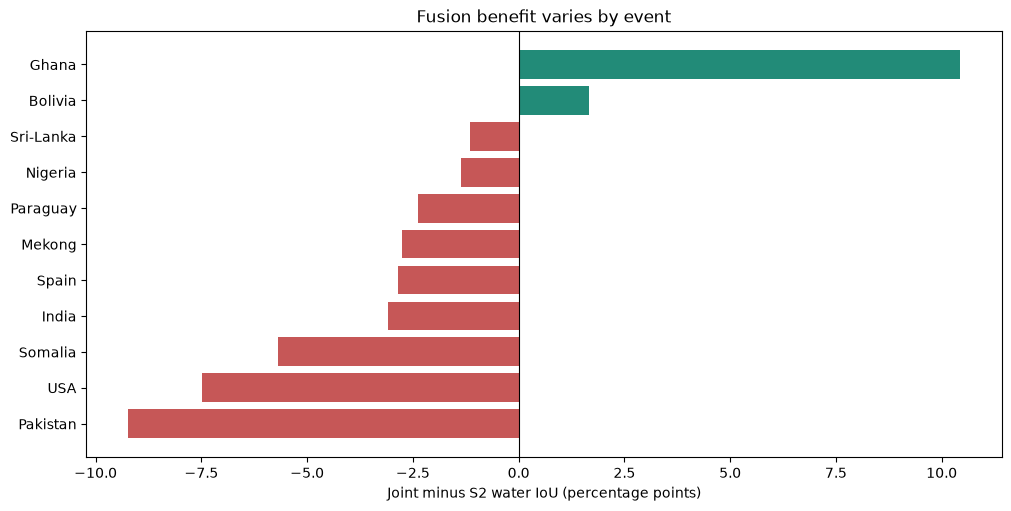

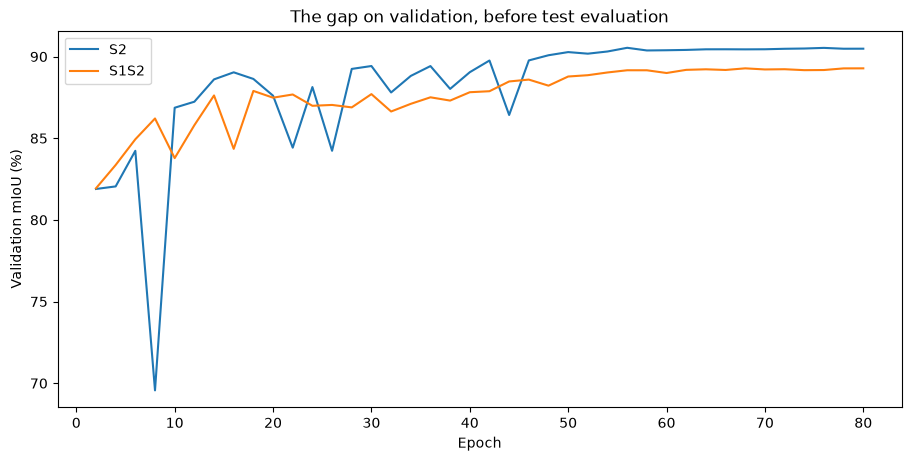

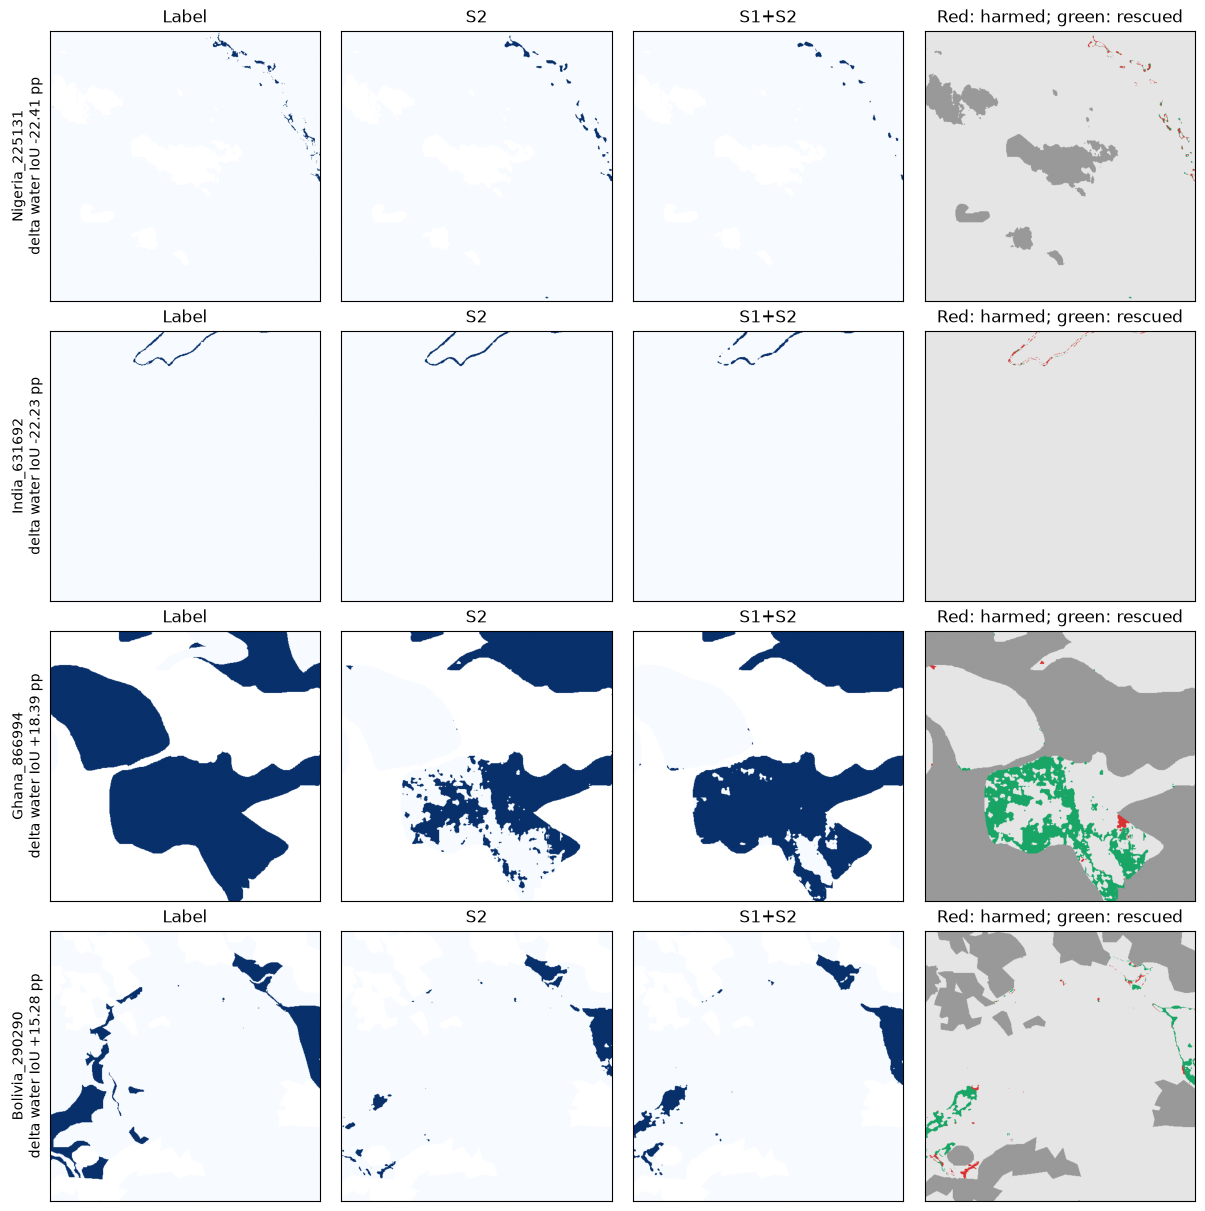

In [4]:
# Visual diagnostics; extremes are explicitly selected, not representative random examples.
fig,ax=plt.subplots(figsize=(10,5),layout='constrained');e=events.sort_values('delta_water_iou_pp');ax.barh(e.region,e.delta_water_iou_pp,color=np.where(e.delta_water_iou_pp<0,'#c65757','#228b78'));ax.axvline(0,color='black',lw=.8);ax.set_xlabel('Joint minus S2 water IoU (percentage points)');ax.set_title('Fusion benefit varies by event');fig.savefig(OUT/'event_deltas.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
for m in ['S2','S1S2']:
    v=HIST[m]['history']['val_miou'];xy=[(i+1,x*100) for i,x in enumerate(v) if x is not None];ax.plot(*zip(*xy),label=m)
ax.set(xlabel='Epoch',ylabel='Validation mIoU (%)',title='The gap on validation, before test evaluation');ax.legend();fig.savefig(OUT/'validation_curves.png',dpi=180);plt.show()
selected=pd.concat([paired[paired.valid_pixels>0].nsmallest(2,'delta_water_iou_pp'),paired[paired.valid_pixels>0].nlargest(2,'delta_water_iou_pp')]).drop_duplicates(['split','chip'])
selected.to_csv(OUT/'visual_selection.csv',index=False)
fig,axes=plt.subplots(len(selected),4,figsize=(12,3*len(selected)),squeeze=False,layout='constrained')
for row,(_,r) in enumerate(selected.iterrows()):
    y,p,harm,rescue=cache[(r.split,r.chip)];valid=np.isin(y,[0,1])
    for j,(label,a) in enumerate([('Label',y),('S2',p['S2']),('S1+S2',p['S1S2'])]):
        axes[row,j].imshow(np.ma.array(a,mask=~valid),vmin=0,vmax=1,cmap='Blues');axes[row,j].set_title(label)
    rgb=np.ones((*y.shape,3))*.90;rgb[~valid]=.6;rgb[harm]=[.85,.2,.2];rgb[rescue]=[.1,.65,.4]
    axes[row,3].imshow(rgb);axes[row,3].set_title('Red: harmed; green: rescued')
    axes[row,0].set_ylabel(r.chip+'\n'+f'delta water IoU {r.delta_water_iou_pp:+.2f} pp')
    for ax in axes[row]:ax.set_xticks([]);ax.set_yticks([])
fig.savefig(OUT/'selected_error_maps.png',dpi=170);plt.show()

In [5]:
# Primary-source literature: distinguish direct evidence from contextual analogies.
literature=[
 {'paper':'GEO-Bench-2 (v2, 2026)','url':'https://arxiv.org/html/2511.15658v2#A6.SS3.SSS6','evidence':'Section 6.3.6 compares optical-only and optical+SAR for TerraMind, DOFA and Clay. PASTIS scores decrease with multimodal input for all tested models; effects elsewhere depend on model/dataset.','relevance':'Direct evidence that GeoFM multimodality can underperform optical-only. Not CROMA or Sen1Floods11.'},
 {'paper':'CROMA (NeurIPS 2023)','url':'https://arxiv.org/pdf/2311.00566','evidence':'Section 3 multimodal setup uses concatenated radar, optical and joint representations. Reported DFC2020 multimodal gains over optical are 4.9 points (Base) and 3.5 points (Large).','relevance':'Counterexample to universal degradation. Different task/head and feature combination from our joint-only UPerNet. No direct matching CROMA/Sen1Floods11 degradation experiment verified.'},
 {'paper':'GEOID-Flood (2026 preprint)','url':'https://arxiv.org/html/2608.02315v1#S5.T3','evidence':'Table 3 frozen TerraMind-B paired flood-loss setup: S1 water IoU 0.873 versus S1+S2 pre-event input followed by post-event S1 at 0.865.','relevance':'An example where adding inputs reduces a metric, but temporal setup and reference modality differ; not S2-only versus simultaneous S1+S2.'}
]
(OUT/'literature.json').write_text(json.dumps(literature,indent=2));display(pd.DataFrame(literature))
limitations=[
 'Only hard prediction masks were saved. Confidence calibration, entropy and probability-level ensembles cannot be evaluated without new inference.',
 'This compares trained configurations; it does not identify the causal effect of the radar sensor. Same seed does not guarantee identical decoder initialization or crop sequence after constructing different encoders.',
 'Frozen joint representations and the absence of an optical skip path are plausible explanations, not proven causes.',
 'Grid checks establish metadata alignment, not perfect physical coregistration. Date gaps are calendar-day metadata, not exact elapsed hours.',
 'Boundary/component diagnostics use hand-label geometry; they cannot establish whether the reference labels are physically correct.',
 'No threshold tuning, model selection or retraining is performed on the test set. Any follow-up tuning must use validation and a fresh final evaluation plan.'
]
(OUT/'limitations.json').write_text(json.dumps(limitations,indent=2))
parts=['<html><head><meta charset="utf-8"><title>Multimodal CROMA diagnosis</title><style>body{font:15px Arial;max-width:1200px;margin:35px auto;color:#243548}table{border-collapse:collapse;font-size:12px}td,th{padding:6px;border:1px solid #ccd4dd}img{max-width:100%}</style></head><body><h1>Why does joint CROMA underperform S2?</h1><p>Read-only diagnosis of saved UPerNet runs. Values in tables are fractions unless labelled pp. No new training.</p>']
for title,df in [('Overall results',summary),('Event diagnosis',events),('Water categories',cat),('Missing-input sensitivity',usable),('Acquisition-gap sensitivity',gap),('Spatial strata',stratum),('Training protocol',protocol),('Architecture differences',architecture)]:parts.extend(['<h2>'+title+'</h2>',df.to_html(index=False,float_format=lambda x:f'{x:.4f}')])
parts.extend(['<h2>Paired event bootstrap</h2><pre>'+html.escape(json.dumps(bootstrap,indent=2))+'</pre>'])
for f in ['event_deltas.png','validation_curves.png','selected_error_maps.png']:parts.append('<img src="'+f+'">')
parts.append('<h2>Literature</h2>')
for item in literature:parts.append('<p><a href="'+item['url']+'">'+item['paper']+'</a>: '+html.escape(item['evidence']+' '+item['relevance'])+'</p>')
parts.append('<h2>Interpretation limits</h2>');parts.extend('<p>'+html.escape(x)+'</p>' for x in limitations)
parts.append('<h2>Follow-up experiments (not executed)</h2><p>Repeat seeds; compare matched optical feature depths; test radar+optical+joint concatenation or an optical residual path; then test limited cross-attention adaptation. Preserve validation-based selection and account for added decoder capacity.</p></body></html>')
(OUT/'diagnostic_report.html').write_text('\n'.join(parts),encoding='utf-8')
print('Saved report:',OUT/'diagnostic_report.html')

,paper,url,evidence,relevance
0,"GEO-Bench-2 (v2, 2026)",https://arxiv.org/html/2511.15658v2#A6.SS3.SSS6,Section 6.3.6 compares optical-only and optica...,Direct evidence that GeoFM multimodality can u...
1,CROMA (NeurIPS 2023),https://arxiv.org/pdf/2311.00566,Section 3 multimodal setup uses concatenated r...,Counterexample to universal degradation. Diffe...
2,GEOID-Flood (2026 preprint),https://arxiv.org/html/2608.02315v1#S5.T3,Table 3 frozen TerraMind-B paired flood-loss s...,An example where adding inputs reduces a metri...


Saved report: reports\multimodal_diagnostics\20261028_095846\diagnostic_report.html
